# MT5 Data Fetcher + Local CSV Loader

This notebook can either:

1. Fetch fresh OHLC data from MetaTrader 5
2. Load previously saved OHLC data from a local CSV file

It supports three MT5 fetch modes:

- `last_n`
- `date_range`
- `max_bars`

The `max_bars` function is kept in the simple original form:

```python
rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, max_bars_request)
```

The output DataFrame keeps these columns:

- `time`
- `open`
- `high`
- `low`
- `close`
- `tick_volume`
- `spread`
- `real_volume`
- `range`
- `body`
- `weekday`
- `ema20`
- `atr14`

It does not include separate `date`, `hour`, `minute`, `upper_wick`, `lower_wick`, or `range_pct` columns.


## 1. Optional package installation

Run this only if packages are missing from your active Python environment.


In [ ]:
# Run only if needed.
# import sys
# !{sys.executable} -m pip install MetaTrader5 pandas matplotlib


## 2. Imports and configuration

Change the settings below.

Use:

```python
USE_LOCAL_CSV = True
```

when you want to load saved data from CSV.

Use:

```python
USE_LOCAL_CSV = False
```

when you want to fetch fresh data from MT5.


In [25]:
import MetaTrader5 as mt5
import pandas as pd
from datetime import datetime, timezone
from pathlib import Path


# ============================================================
# CHOOSE DATA SOURCE
# ============================================================

# True  -> load df from local CSV
# False -> fetch df from MT5
USE_LOCAL_CSV = True

# Used only when USE_LOCAL_CSV = True
CSV_FILE_PATH = r"mt5_data\XAUUSDzero_M5_max_bars.csv"


# ============================================================
# MT5 TERMINAL CONFIG
# ============================================================

MT5_PATH = r"C:\Program Files\AMarkets - MetaTrader 5\terminal64.exe"


# ============================================================
# DATA CONFIG
# ============================================================

SYMBOL = "XAUUSDzero"
TIMEFRAME_NAME = "M5"

TIMEFRAMES = {
    "M1": mt5.TIMEFRAME_M1,
    "M2": mt5.TIMEFRAME_M2,
    "M3": mt5.TIMEFRAME_M3,
    "M4": mt5.TIMEFRAME_M4,
    "M5": mt5.TIMEFRAME_M5,
    "M6": mt5.TIMEFRAME_M6,
    "M10": mt5.TIMEFRAME_M10,
    "M12": mt5.TIMEFRAME_M12,
    "M15": mt5.TIMEFRAME_M15,
    "M20": mt5.TIMEFRAME_M20,
    "M30": mt5.TIMEFRAME_M30,
    "H1": mt5.TIMEFRAME_H1,
    "H2": mt5.TIMEFRAME_H2,
    "H3": mt5.TIMEFRAME_H3,
    "H4": mt5.TIMEFRAME_H4,
    "H6": mt5.TIMEFRAME_H6,
    "H8": mt5.TIMEFRAME_H8,
    "H12": mt5.TIMEFRAME_H12,
    "D1": mt5.TIMEFRAME_D1,
    "W1": mt5.TIMEFRAME_W1,
    "MN1": mt5.TIMEFRAME_MN1,
}

TIMEFRAME = TIMEFRAMES[TIMEFRAME_NAME]


# ============================================================
# MT5 FETCH MODE
# ============================================================
# Used only when USE_LOCAL_CSV = False
#
# Choose one:
# "last_n"      -> fetch latest N candles
# "date_range"  -> fetch from START_DATE to END_DATE
# "max_bars"    -> ask MT5 for MAX_BARS_REQUEST bars

FETCH_MODE = "last_n"


# Used when FETCH_MODE = "last_n"
LAST_N_CANDLES = 10_000


# Used when FETCH_MODE = "date_range"
START_DATE = datetime(2025, 1, 1, 0, 0, tzinfo=timezone.utc)
END_DATE = datetime(2025, 12, 31, 23, 59, tzinfo=timezone.utc)


# Used when FETCH_MODE = "max_bars"
MAX_BARS_REQUEST = 1_000_000


# ============================================================
# OUTPUT CONFIG
# ============================================================

OUTPUT_DIR = Path("mt5_data")
OUTPUT_DIR.mkdir(exist_ok=True)

SAVE_CSV = True


## 3. Helper functions


In [26]:
def connect_to_mt5(mt5_path: str) -> None:
    """Connect to a specific MetaTrader 5 terminal."""
    if not mt5.initialize(path=mt5_path):
        raise RuntimeError(f"MT5 initialize failed: {mt5.last_error()}")

    terminal_info = mt5.terminal_info()
    account_info = mt5.account_info()

    print("Connected to MetaTrader 5")
    print(f"Terminal path: {terminal_info.path}")
    print(f"Terminal name: {terminal_info.name}")
    print(f"Company: {terminal_info.company}")
    print(f"Data path: {terminal_info.data_path}")

    if account_info:
        print(f"Account login: {account_info.login}")
        print(f"Server: {account_info.server}")
        print(f"Account company: {account_info.company}")

    print("-" * 80)


def validate_symbol(symbol: str) -> None:
    """Check that the symbol exists and select it in Market Watch."""
    symbol_info = mt5.symbol_info(symbol)

    if symbol_info is None:
        print(f"Symbol not found: {symbol}")
        print("Similar gold/XAU symbols available:")

        symbols = mt5.symbols_get()
        if symbols:
            for s in symbols:
                name_upper = s.name.upper()
                if "XAU" in name_upper or "GOLD" in name_upper:
                    print(" -", s.name)

        raise RuntimeError(f"Symbol does not exist in this terminal: {symbol}")

    if not mt5.symbol_select(symbol, True):
        raise RuntimeError(f"Could not select symbol: {symbol}. MT5 error: {mt5.last_error()}")

    symbol_info = mt5.symbol_info(symbol)

    print(f"Symbol selected: {symbol_info.name}")
    print(f"Visible: {symbol_info.visible}")
    print(f"Digits: {symbol_info.digits}")
    print(f"Point: {symbol_info.point}")
    print("-" * 80)


def add_candle_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add candle range/body, weekday, EMA20, and ATR14."""
    df = df.copy()

    df["range"] = df["high"] - df["low"]
    df["body"] = (df["close"] - df["open"]).abs()
    df["weekday"] = df["time"].dt.day_name()

    # EMA 20 based on close.
    df["ema20"] = df["close"].ewm(span=20, adjust=False).mean()

    # ATR 14.
    prev_close = df["close"].shift(1)
    high_low = df["high"] - df["low"]
    high_prev_close = (df["high"] - prev_close).abs()
    low_prev_close = (df["low"] - prev_close).abs()

    true_range = pd.concat(
        [high_low, high_prev_close, low_prev_close],
        axis=1
    ).max(axis=1)

    # Wilder-style ATR uses alpha = 1 / period.
    df["atr14"] = true_range.ewm(alpha=1 / 14, adjust=False).mean()

    return df


def clean_dataframe_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Sort, de-duplicate, recalculate features, and keep the final columns."""
    df = df.copy()

    if "time" not in df.columns:
        raise ValueError("DataFrame must contain a 'time' column.")

    df["time"] = pd.to_datetime(df["time"], utc=True)

    required_price_columns = ["open", "high", "low", "close"]
    missing_columns = [col for col in required_price_columns if col not in df.columns]

    if missing_columns:
        raise ValueError(f"Missing required price columns: {missing_columns}")

    df = (
        df
        .sort_values("time")
        .drop_duplicates(subset=["time"])
        .reset_index(drop=True)
    )

    df = add_candle_features(df)

    desired_columns = [
        "time",
        "open",
        "high",
        "low",
        "close",
        "tick_volume",
        "spread",
        "real_volume",
        "range",
        "body",
        "weekday",
        "ema20",
        "atr14",
    ]

    existing_columns = [col for col in desired_columns if col in df.columns]
    df = df[existing_columns]

    return df


def convert_rates_to_dataframe(rates) -> pd.DataFrame:
    """Convert MT5 rates array to a clean pandas DataFrame."""
    if rates is None:
        raise RuntimeError(f"MT5 returned None. Error: {mt5.last_error()}")

    if len(rates) == 0:
        raise RuntimeError("MT5 returned 0 rows. Try a smaller date range or load more chart history.")

    df = pd.DataFrame(rates)
    df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)

    return clean_dataframe_columns(df)


def load_dataframe_from_csv(csv_file_path: str) -> pd.DataFrame:
    """
    Load previously saved MT5 candle data from a local CSV file.

    The CSV should contain at least:
    time, open, high, low, close

    If range/body/weekday/ema20/atr14 already exist, they are recalculated.
    """
    df = pd.read_csv(csv_file_path)
    return clean_dataframe_columns(df)


def fetch_last_n_candles(symbol: str, timeframe: int, n_candles: int) -> pd.DataFrame:
    """Fetch the latest N candles."""
    rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, n_candles)
    return convert_rates_to_dataframe(rates)


def fetch_date_range(symbol: str, timeframe: int, start_date: datetime, end_date: datetime) -> pd.DataFrame:
    """Fetch candles from start_date to end_date. Dates should be timezone-aware UTC datetimes."""
    rates = mt5.copy_rates_range(symbol, timeframe, start_date, end_date)
    return convert_rates_to_dataframe(rates)


def fetch_max_available_bars(symbol: str, timeframe: int, max_bars_request: int) -> pd.DataFrame:
    """
    Try to fetch the maximum available bars.

    This asks MT5 for a large number of bars from the latest candle backward.
    The terminal/broker may return less than requested.
    """
    rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, max_bars_request)
    return convert_rates_to_dataframe(rates)


def fetch_data(
    mode: str,
    symbol: str,
    timeframe: int,
    last_n_candles: int = 10_000,
    start_date: datetime = None,
    end_date: datetime = None,
    max_bars_request: int = 1_000_000,
) -> pd.DataFrame:
    """Main fetch function with three supported modes."""
    if mode == "last_n":
        print(f"Fetching latest {last_n_candles:,} candles for {symbol}...")
        return fetch_last_n_candles(symbol, timeframe, last_n_candles)

    if mode == "date_range":
        if start_date is None or end_date is None:
            raise ValueError("start_date and end_date are required for mode='date_range'.")

        print(f"Fetching {symbol} from {start_date} to {end_date}...")
        return fetch_date_range(symbol, timeframe, start_date, end_date)

    if mode == "max_bars":
        print(f"Trying to fetch up to {max_bars_request:,} bars for {symbol}...")
        return fetch_max_available_bars(symbol, timeframe, max_bars_request)

    raise ValueError("Invalid mode. Use 'last_n', 'date_range', or 'max_bars'.")


def save_dataframe_to_csv(df: pd.DataFrame, symbol: str, timeframe_name: str, fetch_mode: str) -> Path:
    """Save fetched or loaded data to CSV."""
    output_file = OUTPUT_DIR / f"{symbol}_{timeframe_name}_{fetch_mode}.csv"
    df.to_csv(output_file, index=False)
    return output_file


## 4. Load from CSV or fetch from MT5

Run this cell to create the main DataFrame named `df`.

All later analysis cells use this same `df`, whether it came from CSV or MT5.


In [27]:
if USE_LOCAL_CSV:
    print(f"Loading data from CSV: {CSV_FILE_PATH}")

    df = load_dataframe_from_csv(CSV_FILE_PATH)

    print("CSV loaded.")
    print(f"Rows: {len(df):,}")
    print(f"First candle: {df['time'].min()}")
    print(f"Last candle: {df['time'].max()}")

else:
    connect_to_mt5(MT5_PATH)
    validate_symbol(SYMBOL)

    try:
        df = fetch_data(
            mode=FETCH_MODE,
            symbol=SYMBOL,
            timeframe=TIMEFRAME,
            last_n_candles=LAST_N_CANDLES,
            start_date=START_DATE,
            end_date=END_DATE,
            max_bars_request=MAX_BARS_REQUEST,
        )

        print("Fetch complete.")
        print(f"Rows: {len(df):,}")
        print(f"First candle: {df['time'].min()}")
        print(f"Last candle: {df['time'].max()}")

        if SAVE_CSV:
            output_file = save_dataframe_to_csv(df, SYMBOL, TIMEFRAME_NAME, FETCH_MODE)
            print(f"Saved to: {output_file}")

    finally:
        mt5.shutdown()
        print("MT5 connection closed.")


Loading data from CSV: mt5_data\XAUUSDzero_M5_max_bars.csv
CSV loaded.
Rows: 90,000
First candle: 2025-02-10 21:45:00+00:00
Last candle: 2026-05-20 12:30:00+00:00


## 5. Preview the data


In [28]:
df.head()


,time,open,high,low,close,tick_volume,spread,real_volume,range,body,weekday,ema20,atr14
0,2025-02-10 21:45:00+00:00,2904.95,2905.42,2904.60,2904.60,502,0,0,0.82,0.35,Monday,2904.600000,0.820000
1,2025-02-10 21:50:00+00:00,2904.64,2904.74,2903.43,2903.68,679,0,0,1.31,0.96,Monday,2904.512381,0.855000
2,2025-02-10 21:55:00+00:00,2903.64,2904.55,2903.34,2904.41,711,0,0,1.21,0.77,Monday,2904.502630,0.880357
3,2025-02-10 22:00:00+00:00,2904.40,2904.94,2903.67,2904.04,673,0,0,1.27,0.36,Monday,2904.458570,0.908189
4,2025-02-10 22:05:00+00:00,2904.05,2904.42,2903.48,2903.54,634,0,0,0.94,0.51,Monday,2904.371087,0.910461


In [29]:
df.tail()


,time,open,high,low,close,tick_volume,spread,real_volume,range,body,weekday,ema20,atr14
89995,2026-05-20 12:10:00+00:00,4482.19,4482.51,4479.93,4480.36,419,0,0,2.58,1.83,Wednesday,4481.744043,5.254938
89996,2026-05-20 12:15:00+00:00,4480.09,4482.60,4479.23,4482.60,419,0,0,3.37,2.51,Wednesday,4481.825562,5.120300
89997,2026-05-20 12:20:00+00:00,4482.63,4483.69,4478.91,4479.50,381,0,0,4.78,3.13,Wednesday,4481.604080,5.095993
89998,2026-05-20 12:25:00+00:00,4479.46,4479.61,4473.02,4474.29,434,0,0,6.59,5.17,Wednesday,4480.907501,5.202708
89999,2026-05-20 12:30:00+00:00,4474.20,4480.05,4473.01,4479.87,267,1,0,7.04,5.67,Wednesday,4480.808692,5.333943


## 6. Quick checks


In [30]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   time         90000 non-null  datetime64[ns, UTC]
 1   open         90000 non-null  float64            
 2   high         90000 non-null  float64            
 3   low          90000 non-null  float64            
 4   close        90000 non-null  float64            
 5   tick_volume  90000 non-null  int64              
 6   spread       90000 non-null  int64              
 7   real_volume  90000 non-null  int64              
 8   range        90000 non-null  float64            
 9   body         90000 non-null  float64            
 10  weekday      90000 non-null  object             
 11  ema20        90000 non-null  float64            
 12  atr14        90000 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(8), int64(3), object(1)
memory usage: 8.9

In [31]:
df.describe()


,open,high,low,close,tick_volume,spread,real_volume,range,body,ema20,atr14
count,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.0,90000.000000,90000.000000,90000.000000,90000.000000
mean,3909.833531,3912.077878,3907.479090,3909.849954,530.380733,1.006033,0.0,4.598788,2.332318,3909.683576,4.611456
std,707.389448,708.390178,706.293053,707.380761,200.679631,3.612566,0.0,4.929040,3.388843,707.371236,3.870447
min,2833.740000,2836.890000,2832.760000,2833.890000,12.000000,0.000000,0.0,0.150000,0.000000,2842.819154,0.636371
25%,3327.170000,3328.490000,3325.880000,3327.190000,392.000000,0.000000,0.0,1.990000,0.580000,3327.452931,2.358829
50%,3815.725000,3817.385000,3813.675000,3815.780000,511.000000,0.000000,0.0,3.250000,1.360000,3814.416444,3.609285
75%,4555.335000,4558.760000,4551.902500,4555.395000,650.000000,0.000000,0.0,5.460000,2.830000,4555.657237,5.547850
max,5588.180000,5596.760000,5581.740000,5588.560000,1561.000000,66.000000,0.0,208.740000,123.020000,5570.422378,61.179895


## 7. Average candle range by weekday

This table groups candles by weekday and summarizes the `range` column.

```python
range = high - low
```

Column meanings:

- `count`: number of candles in that weekday group
- `mean`: average candle range
- `median`: middle candle range
- `std`: standard deviation of candle ranges
- `min`: smallest candle range
- `max`: largest candle range


In [32]:
weekday_stats = (
    df.groupby("weekday")["range"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

weekday_stats


,count,mean,median,std,min,max
weekday,,,,,,
Monday,18093,4.883955,3.31,5.756924,0.24,137.82
Thursday,17592,4.678017,3.29,5.330482,0.28,208.74
Friday,17528,4.641848,3.22,5.149472,0.15,91.83
Tuesday,18492,4.453368,3.21,4.314929,0.17,91.07
Wednesday,18295,4.346315,3.23,3.876529,0.16,65.31


## 8. Candle range distribution

This gives percentile levels for candle range.


In [33]:
range_distribution = df["range"].quantile([
    0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
]).to_frame(name="range")

range_distribution


,range
0.01,0.6600
0.05,1.0100
0.10,1.3000
0.25,1.9900
0.50,3.2500
0.75,5.4600
0.90,8.9000
0.95,12.2700
0.99,24.4101


## 9. Optional plots


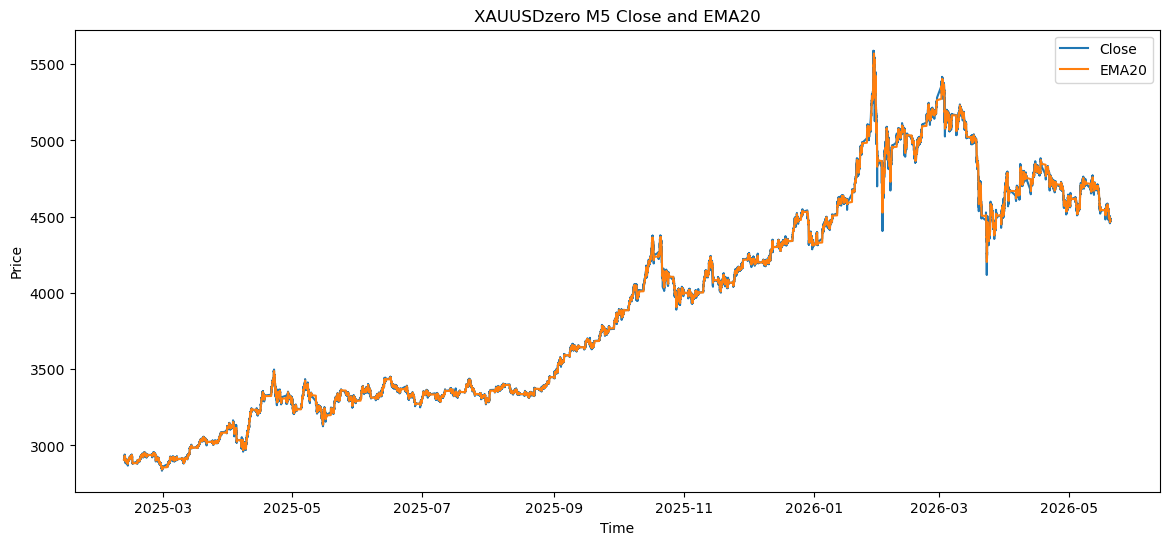

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(df["time"], df["close"], label="Close")
plt.plot(df["time"], df["ema20"], label="EMA20")
plt.title(f"{SYMBOL} {TIMEFRAME_NAME} Close and EMA20")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()


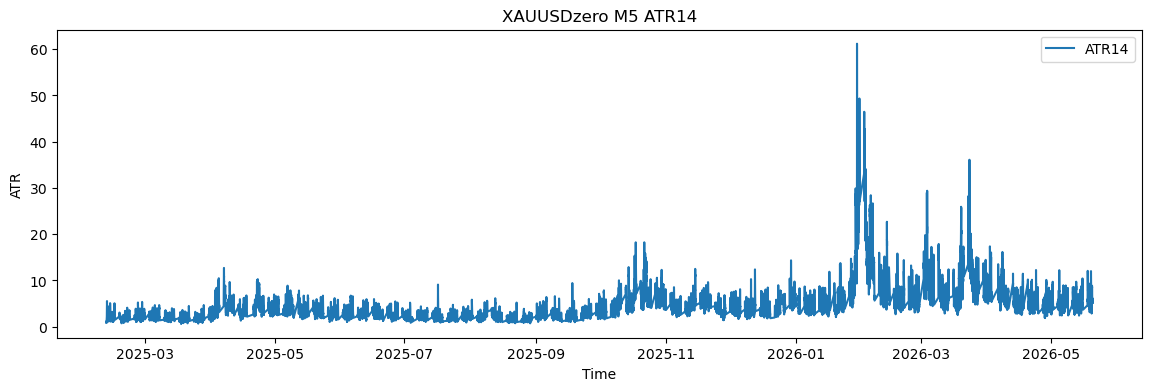

In [35]:
plt.figure(figsize=(14, 4))
plt.plot(df["time"], df["atr14"], label="ATR14")
plt.title(f"{SYMBOL} {TIMEFRAME_NAME} ATR14")
plt.xlabel("Time")
plt.ylabel("ATR")
plt.legend()
plt.show()


## 10. Notes

- When `USE_LOCAL_CSV = True`, no MT5 connection is opened.
- When `USE_LOCAL_CSV = False`, the notebook fetches fresh data from MT5.
- CSV loading recalculates `range`, `body`, `weekday`, `ema20`, and `atr14` to keep them consistent.
- The simple `max_bars` mode can fail if `MAX_BARS_REQUEST` is too large for the terminal to handle in one request. Lower `MAX_BARS_REQUEST` if needed.
